In [ ]:

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    pairwise_distances_argmin,
    classification_report,
    accuracy_score,
    silhouette_score
)


In [2]:

# Load datasets
train = pd.read_csv("../training_image_features.csv")
test = pd.read_csv("../testing_image_features.csv")

TARGET = "Condition_Class"
CLASSES = ["Excellent", "Good", "Fair", "Poor"]

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

print("\nTraining Dataset:")
display(train.head())

print("\nTesting Dataset:")
display(test.head())


Training Dataset Shape: (10058, 43)
Testing Dataset Shape: (3224, 43)

Training Dataset:


,Sample_ID,Image_ID,Material_Type,Material_Subtype,Source,Exposure_Type,Crack_Level,Surface_Damage,Breakage_Level,Discoloration_Level,...,dark_pixel_ratio,bright_pixel_ratio,mean_hue,mean_saturation,saturation_std,contour_area,contour_perimeter,circularity,solidity,extent
0,TRAINING_00001,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.007217,0.250679,16.328107,103.354121,34.788167,24050.0,2086.576892,0.069415,0.645430,0.460799
1,TRAINING_00002,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,3.5,2,Moderate,...,0.074190,0.022587,25.591271,61.989752,18.395387,15420.0,665.754394,0.437186,0.903736,0.635038
2,TRAINING_00003,1.jpg,tile,Standard,Demolition_Site,Exterior_Weathered,2,3.2,2,High,...,0.030780,0.677715,26.294677,69.389570,18.294682,25750.5,698.114786,0.663960,0.976915,0.710672
3,TRAINING_00004,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,4,3.2,3,Moderate,...,0.230558,0.033828,41.511739,83.602221,28.279230,11908.5,1237.869180,0.097660,0.761900,0.616573
4,TRAINING_00005,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.136304,0.361647,29.703155,61.738122,22.880945,16204.5,963.702659,0.219260,0.837139,0.603520



Testing Dataset:


,Sample_ID,Image_ID,Material_Type,Material_Subtype,Source,Exposure_Type,Crack_Level,Surface_Damage,Breakage_Level,Discoloration_Level,...,dark_pixel_ratio,bright_pixel_ratio,mean_hue,mean_saturation,saturation_std,contour_area,contour_perimeter,circularity,solidity,extent
0,TESTING_00001,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,3,2.8,3,Moderate,...,0.240497,0.000000,34.526890,89.606725,35.372008,10676.0,673.612259,0.295664,0.848480,0.600315
1,TESTING_00002,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,3.5,3,Moderate,...,0.233785,0.014462,24.960123,64.279815,23.678327,8413.5,669.511754,0.235869,0.860320,0.542877
2,TESTING_00003,1.jpg,tile,Standard,Demolition_Site,Exterior_Weathered,3,3.2,3,High,...,0.050909,0.022794,16.593875,76.140166,23.205921,15847.5,537.511753,0.689278,0.971911,0.592807
3,TESTING_00004,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,2,1.8,3,Low,...,0.414074,0.000000,65.767680,77.961949,32.625311,14097.5,822.565577,0.261825,0.838738,0.549610
4,TESTING_00005,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,4.2,3,High,...,0.142847,0.214164,21.420692,66.502581,23.841934,15512.5,955.962545,0.213309,0.771363,0.559110


In [3]:

# Exclude target-related scores
exclude = {
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability"
}

# Select numeric image features
features = [
    col for col in train.select_dtypes(include=np.number).columns
    if col not in exclude
]

print("Number of Features:", len(features))
print("\nSelected Features:")
print(features)


Number of Features: 26

Selected Features:
['Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Deformation_Level', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [4]:

# Extract selected features
X_train = train[features].replace([np.inf, -np.inf], np.nan)
X_test = test[features].replace([np.inf, -np.inf], np.nan)

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Preprocessing Completed Successfully")


Training Data Shape: (10058, 26)
Testing Data Shape: (3224, 26)
Preprocessing Completed Successfully


In [5]:

# Initialize K-Means model
model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit model on training data
train_clusters = model.fit_predict(X_train)

# Predict clusters for testing data
test_clusters = model.predict(X_test)

print("K-Means Clustering Completed")
print("\nCluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())


K-Means Clustering Completed

Cluster Distribution:
0    2885
1    1022
2    2531
3    3620
Name: count, dtype: int64


In [6]:

# Map clusters to majority condition classes
cluster_mapping = {}

for cluster in range(4):
    labels = train.loc[
        train_clusters == cluster, TARGET
    ]

    if len(labels) > 0:
        cluster_mapping[cluster] = labels.mode().iloc[0]
    else:
        cluster_mapping[cluster] = train[TARGET].mode().iloc[0]

print("Cluster to Condition Mapping:")
print(cluster_mapping)


Cluster to Condition Mapping:
{0: 'Fair', 1: 'Fair', 2: 'Fair', 3: 'Fair'}


In [7]:

# Predict testing classes
y_pred = np.array([
    cluster_mapping[c] for c in test_clusters
])

y_test = test[TARGET].astype(str)

print("Predicted Classes:")
print(pd.Series(y_pred).value_counts())

print("\nActual Classes:")
print(y_test.value_counts())


Predicted Classes:
Fair    3224
Name: count, dtype: int64

Actual Classes:
Condition_Class
Fair         2193
Good          716
Poor          274
Excellent      41
Name: count, dtype: int64


In [8]:

# Evaluate K-Means
print("K-Means Clustering")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=CLASSES,
    zero_division=0
))

# Evaluate cluster separation
silhouette = silhouette_score(
    X_train,
    train_clusters,
    sample_size=2000,
    random_state=42
)

print("Silhouette Score:", silhouette)

print("Inertia:", model.inertia_)


K-Means Clustering
Accuracy: 0.6802109181141439

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.00      0.00      0.00        41
        Good       0.00      0.00      0.00       716
        Fair       0.68      1.00      0.81      2193
        Poor       0.00      0.00      0.00       274

    accuracy                           0.68      3224
   macro avg       0.17      0.25      0.20      3224
weighted avg       0.46      0.68      0.55      3224

Silhouette Score: 0.1658769633155519
Inertia: 155863.85248365445


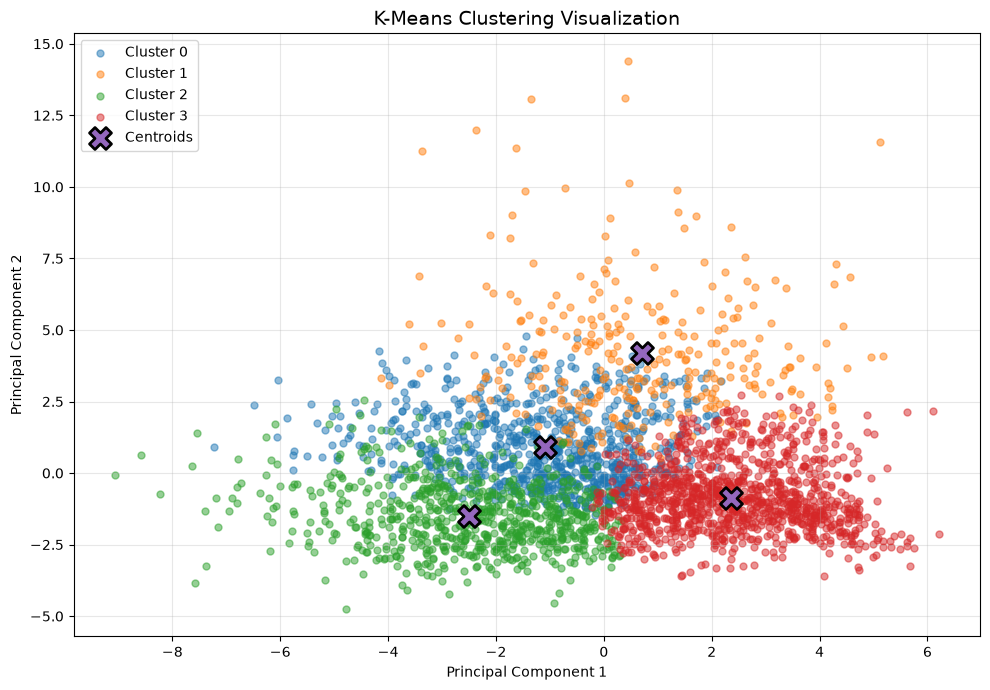

K-Means visualization completed successfully!
Number of clusters: 4
Samples visualized: 3000
Explained variance: 0.4626651661424077


In [4]:

# K-MEANS CLUSTER VISUALIZATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Load training dataset
train = pd.read_csv("../training_image_features.csv")

# Select numerical features
exclude = {
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability"
}

features = [
    col for col in train.select_dtypes(include=np.number).columns
    if col not in exclude
]

# Clean the dataset
X = train[features].replace([np.inf, -np.inf], np.nan)

# Handle missing values
imputer = SimpleImputer(strategy="median")
X = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans_vis = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_vis.fit_predict(X)

# Select samples for visualization
np.random.seed(42)

sample_size = min(3000, len(X))

sample_indices = np.random.choice(
    len(X),
    sample_size,
    replace=False
)

X_sample = X[sample_indices]
sample_labels = cluster_labels[sample_indices]

# Reduce dimensions using PCA
pca_vis = PCA(n_components=2)

X_2d = pca_vis.fit_transform(X_sample)

# Transform cluster centroids
centroids_2d = pca_vis.transform(
    kmeans_vis.cluster_centers_
)

# Plot clusters
plt.figure(figsize=(10, 7))

for cluster in range(4):

    plt.scatter(
        X_2d[sample_labels == cluster, 0],
        X_2d[sample_labels == cluster, 1],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=25
    )

# Plot centroids
plt.scatter(
    centroids_2d[:, 0],
    centroids_2d[:, 1],
    marker="X",
    s=250,
    edgecolors="black",
    linewidths=2,
    label="Centroids"
)

plt.title("K-Means Clustering Visualization", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("K-Means visualization completed successfully!")
print("Number of clusters:", 4)
print("Samples visualized:", sample_size)
print("Explained variance:", pca_vis.explained_variance_ratio_.sum())


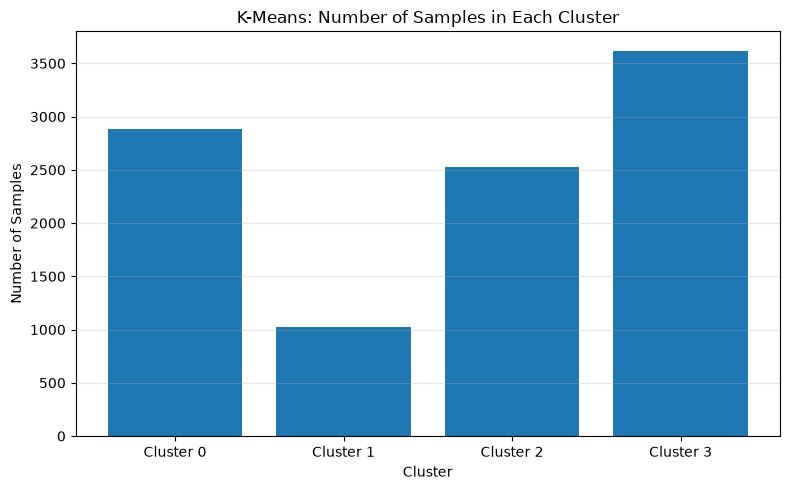

Cluster counts: [2885 1022 2531 3620]


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load training dataset
train_graph = pd.read_csv("../training_image_features.csv")

# Select numerical features and exclude target-related columns
excluded_columns = [
    "Condition_Class",
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability"
]

feature_columns_graph = [
    col for col in train_graph.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

X_graph = train_graph[feature_columns_graph].replace(
    [np.inf, -np.inf], np.nan
)

# Handle missing values
imputer_graph = SimpleImputer(strategy="median")
X_graph = imputer_graph.fit_transform(X_graph)

# Scale features
scaler_graph = StandardScaler()
X_graph_scaled = scaler_graph.fit_transform(X_graph)

# Train K-Means
graph_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

graph_train_clusters = graph_kmeans.fit_predict(X_graph_scaled)

# Count samples in each cluster
cluster_counts = np.bincount(graph_train_clusters, minlength=4)

# Plot graph
plt.figure(figsize=(8, 5))

plt.bar(
    [f"Cluster {i}" for i in range(4)],
    cluster_counts
)

plt.title("K-Means: Number of Samples in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Cluster counts:", cluster_counts)


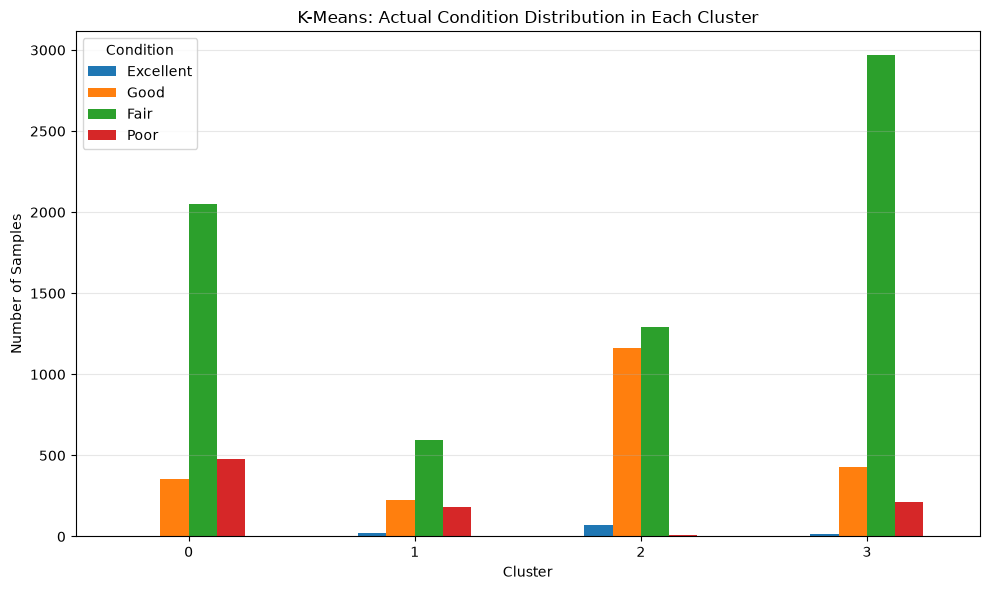

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

clusters = KMeans(
    n_clusters=4, random_state=42, n_init=10
).fit_predict(X)

distribution = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    train_graph["Condition_Class"].reset_index(drop=True)
)

distribution = distribution.reindex(
    columns=["Excellent", "Good", "Fair", "Poor"],
    fill_value=0
)

distribution.plot(kind="bar", figsize=(10, 6))

plt.title("K-Means: Actual Condition Distribution in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend(title="Condition")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


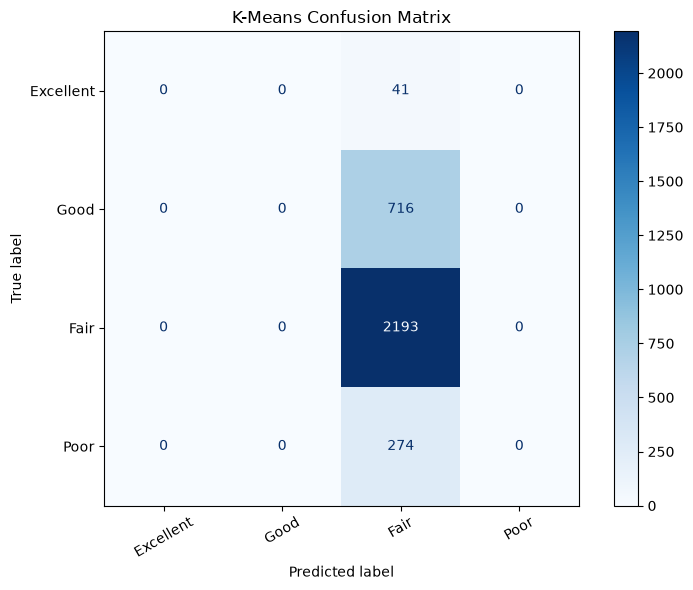

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

train_graph = pd.read_csv("../training_image_features.csv")
test_graph = pd.read_csv("../testing_image_features.csv")

target = "Condition_Class"
classes = ["Excellent", "Good", "Fair", "Poor"]

excluded = [
    target, "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X_train = train_graph[features].replace([np.inf, -np.inf], np.nan)
X_test = test_graph.reindex(columns=features).replace(
    [np.inf, -np.inf], np.nan
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

train_clusters = KMeans(
    n_clusters=4, random_state=42, n_init=10
).fit_predict(X_train)

test_clusters_model = KMeans(
    n_clusters=4, random_state=42, n_init=10
)
test_clusters_model.fit(X_train)

test_clusters = test_clusters_model.predict(X_test)

mapping = {}
y_train = train_graph[target].reset_index(drop=True)

for cluster in range(4):
    labels = y_train[train_clusters == cluster]
    mapping[cluster] = labels.mode().iloc[0] if len(labels) else "Fair"

predictions = pd.Series(test_clusters).map(mapping)

cm = confusion_matrix(
    test_graph[target], predictions, labels=classes
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    cm, display_labels=classes
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("K-Means Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
